# Chapter 19 | Worked solutions

*Translation and Summarization*

Work through all twelve exercises. Begin with the facts a task must preserve,
then align training targets, multiply path probabilities, and count reference
matches. The Python investigations expose padding and stopping rules. The
last four exercises connect search and source evidence to evaluation design.
The written edition keeps every explanation and plot; the notebook PDF adds
code and saved results. Exercises 9-12 are optional extensions.

## Setup

Open this notebook inside `transformers-book`. Install `requirements.txt`,
`matplotlib`, and `jupyterlab`, then run all cells in order on CPU. No model or
dataset download is needed. The optional encoder-decoder update in the chapter
is tested separately with PyTorch. The truncation illustration below uses word
tokens to expose a boundary; it is not a pretrained tokenizer or model run.
Floating-point comparisons declare tolerances. Counts and token rows are
checked exactly.

In [1]:
from pathlib import Path
import sys
import math
from collections import Counter
import numpy as np
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt

for repo_root in (Path.cwd(), *Path.cwd().parents):
    if (repo_root / "examples/ch19_generation/model.py").is_file():
        sys.path.insert(0, str(repo_root))
        break
else:
    raise FileNotFoundError("Open this notebook inside transformers-book.")

from examples.ch19_generation.model import (
    PAD, BOS, EOS, collate_pairs, beam_search,
    clipped_ngram_precision, lcs_length, rouge_l,
)
print("Ready: offline NumPy examples and source-audit fixtures")

Ready: offline NumPy examples and source-audit fixtures


## 1. Decide what must be preserved

A translation must preserve the ferry's identity as the last departure, its
actual departure time of 19:10, the thirty passengers, and the gate inspection
as the cause of the delay. Word order and time formatting may change with
language. The factual relations must remain the same.

For a passenger asking why it was late, one possible summary is: "The last
ferry departed at 19:10 after a gate inspection delayed it." This keeps the
cause and actual departure time. The passenger count is incidental to that
question. A different audience could need it, so the omission is a decision
under the stated task, not a universal rule for summarization.

This selection is an explicit annotation of the example, not an automatic
test of semantic equivalence. The notebook records the two chosen facts.

In [2]:
facts = {
    "departure time: 19:10": True,
    "passengers: thirty": False,
    "delay caused by gate inspection": True,
}
assert sum(facts.values()) == 2
for fact, keep in facts.items():
    print(("Keep: " if keep else "Omit for this task: ") + fact)

Keep: departure time: 19:10
Omit for this task: passengers: thirty
Keep: delay caused by gate inspection


## 2. Align two target lengths

Target $(5,7,6)$ produces decoder input $(1,5,7,6)$ and labels $(5,7,6,2)$.
Target $(8,9)$ produces input $(1,8,9)$ and labels $(8,9,2)$ before padding.
Pad the shorter rows to width four with zero:

$$
Y_{\mathrm{in}}=\begin{bmatrix}1&5&7&6\\1&8&9&0\end{bmatrix},
\qquad
Y_{\mathrm{target}}=\begin{bmatrix}5&7&6&2\\8&9&2&0\end{bmatrix}.
$$

Read corresponding columns within a row. In the second row's third column,
input 9 predicts EOS, whose ID is 2. In the fourth column, the label is padding
and contributes nothing to the loss. The first row has four supervised
positions and the second has three: seven in total, including both EOS labels.
Teacher forcing gives each prediction the reference prefix; a causal mask
blocks later decoder inputs. The loss mask handles padding separately.

In [3]:
_, shifted_inputs, shifted_labels = collate_pairs([
    ([3], [5, 7, 6]), ([4], [8, 9]),
])
np.testing.assert_array_equal(shifted_inputs, [[1,5,7,6],[1,8,9,0]])
np.testing.assert_array_equal(shifted_labels, [[5,7,6,2],[8,9,2,0]])
assert (shifted_labels != PAD).sum() == 7
print("Decoder input:\n", shifted_inputs)
print("Labels:\n", shifted_labels)
print("Loss mask:\n", (shifted_labels != PAD).astype(int))

Decoder input:
 [[1 5 7 6]
 [1 8 9 0]]
Labels:
 [[5 7 6 2]
 [8 9 2 0]]
Loss mask:
 [[1 1 1 1]
 [1 1 1 0]]


## 3. Compare complete paths

Multiply conditional probabilities along each path, including the end marker.
Choosing A and then EOS has probability $0.7(0.6)=0.42$. Going through C adds
one more factor; its EOS probability is one.

| Completed path | Product | Probability |
| --- | --- | --- |
| A, EOS | $0.7(0.6)$ | 0.42 |
| A, C, EOS | $0.7(0.4)(1)$ | 0.28 |
| B, EOS | $0.3(0.9)$ | 0.27 |
| B, C, EOS | $0.3(0.1)(1)$ | 0.03 |

These four disjoint complete paths exhaust this tree and sum to one. Greedy
decoding chooses A at the root and EOS after A. It happens to find the globally
most probable complete path here. The chapter's different tree, with 0.60/0.40
at the root, shows that this success is not guaranteed.

In [4]:
paths = {"A EOS": .7*.6, "A C EOS": .7*.4,
         "B EOS": .3*.9, "B C EOS": .3*.1}
assert math.isclose(sum(paths.values()), 1)
assert max(paths, key=paths.get) == "A EOS"
for path, probability in paths.items():
    print(f"{path:8s}  {probability:.2f}")

A EOS     0.42
A C EOS   0.28
B EOS     0.27
B C EOS   0.03


## 4. Count repeated and ordered matches

Candidate `red red ferry departs` has four tokens. Reference
`red ferry departs at noon` has five. Clip each candidate unigram count by
its reference count:

| Token | Candidate count | Reference count | Clipped count |
| --- | --- | --- | --- |
| red | 2 | 1 | 1 |
| ferry | 1 | 1 | 1 |
| departs | 1 | 1 | 1 |

The numerator is three. The denominator still counts every candidate token,
including the repeated red, giving $3/4=0.75$. A longest common subsequence
is `red ferry departs`, of length three. Either candidate red can supply the
single reference red; one reference occurrence cannot be reused. The reference
tokens at and noon have no candidate matches, so a longer subsequence is
impossible. Matching order is required, but adjacency is not.

In [5]:
hand_candidate = "red red ferry departs".split()
hand_reference = "red ferry departs at noon".split()
clipped = Counter(hand_candidate) & Counter(hand_reference)
assert sum(clipped.values()) == 3
assert clipped_ngram_precision(hand_candidate, hand_reference, 1) == .75
assert lcs_length(hand_candidate, hand_reference) == 3
print("Clipped counts:", dict(clipped))
print("Unigram precision:", 3/4)
print("LCS length:", lcs_length(hand_candidate, hand_reference))

Clipped counts: {'red': 1, 'ferry': 1, 'departs': 1}
Unigram precision: 0.75
LCS length: 3


The following table makes the LCS calculation visible. Row $i$ represents
the first $i$ candidate tokens; column $j$ represents the first $j$ reference
tokens. Empty prefixes give zero. Matching last tokens add one to the diagonal
predecessor; a mismatch takes the larger count from above or left. At the
second red, the count stays one: there is still only one red on the reference
side. The last cell gives three. The full table is for teaching; the canonical
helper only retains the previous and current rows.

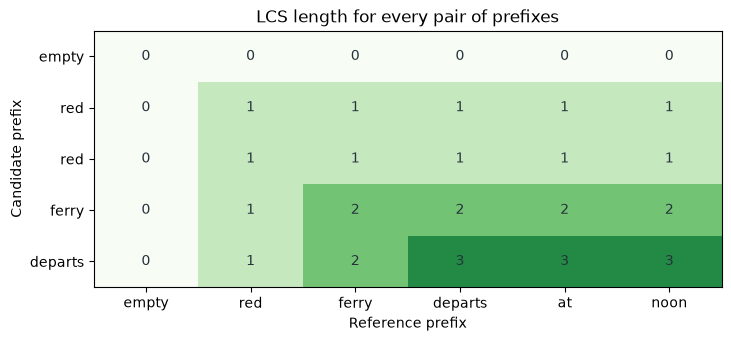

In [6]:
D = np.zeros((len(hand_candidate)+1, len(hand_reference)+1), dtype=int)
for i, word in enumerate(hand_candidate, 1):
    for j, other in enumerate(hand_reference, 1):
        D[i, j] = (D[i-1, j-1]+1 if word == other
                   else max(D[i-1, j], D[i, j-1]))
assert D[-1,-1] == lcs_length(hand_candidate, hand_reference)
fig, ax = plt.subplots(figsize=(7.2, 3.3), constrained_layout=True)
ax.imshow(D, cmap="Greens", vmin=0, vmax=4, aspect="auto")
ax.set(xticks=range(D.shape[1]), xticklabels=["empty"]+hand_reference,
       yticks=range(D.shape[0]), yticklabels=["empty"]+hand_candidate,
       xlabel="Reference prefix", ylabel="Candidate prefix",
       title="LCS length for every pair of prefixes")
for (i,j), value in np.ndenumerate(D):
    ax.text(j, i, str(value), ha="center", va="center", color="#26323D")
plt.show()

## 5. Aggregate counts before dividing

The two match counts are 3 and 4; the candidate lengths are 4 and 10.
Corpus unigram precision is

$$p_1=\frac{3+4}{4+10}=\frac{7}{14}=0.5.$$

The mean of the two sentence precisions is

$$\frac{1}{2}\left(\frac34+\frac4{10}\right)=0.575.$$

The corpus calculation gives equal weight to each candidate token. The
sentence average gives equal weight to each example, so the four-token example
has as much influence as the ten-token example. Neither quantity is complete
BLEU: one also needs the specified higher n-gram orders, their geometric
combination, and the brevity penalty. A zero numerator and a zero denominator
are different situations. The helper returns `None` when the candidate has no
n-grams of the requested order; do not turn that into a perfect match.

In [7]:
corpus_candidates = [hand_candidate,
    "the blue bus arrived late after a long snowy diversion".split()]
corpus_references = [hand_reference, "blue bus arrived late".split()]
lengths = [len(c) for c in corpus_candidates]
matches = [sum((Counter(c) & Counter(r)).values())
           for c,r in zip(corpus_candidates,corpus_references)]
assert lengths == [4,10] and matches == [3,4]
corpus_precision = sum(matches)/sum(lengths)
sentence_average = np.mean([m/n for m,n in zip(matches,lengths)])
np.testing.assert_allclose([corpus_precision,sentence_average],[.5,.575],
                           rtol=0,atol=1e-15)
assert clipped_ngram_precision(["bus"],["bus"],2) is None
print("Corpus unigram precision:", corpus_precision)
print("Mean sentence precision:", sentence_average)
print("One-token bigram component: undefined (None)")

Corpus unigram precision: 0.5
Mean sentence precision: 0.575
One-token bigram component: undefined (None)


The bars show the two aggregations of exactly the same matches. Their
difference comes from weighting, not from a new prediction or tokenizer.

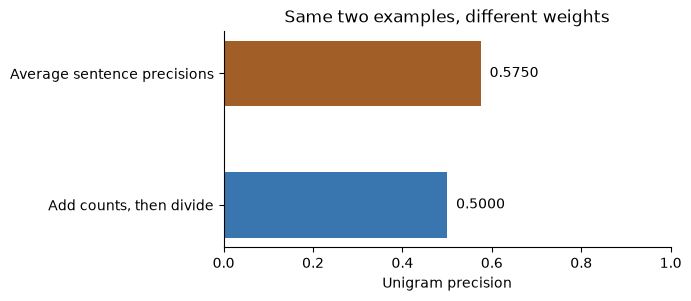

In [8]:
fig, ax = plt.subplots(figsize=(6.8, 2.9), constrained_layout=True)
scores = [corpus_precision,sentence_average]
ax.barh(["Add counts, then divide","Average sentence precisions"],scores,
        color=["#3976AF","#A25E27"],height=.5)
ax.set(xlim=(0,1),xlabel="Unigram precision",title="Same two examples, different weights")
for i,value in enumerate(scores):ax.text(value+.02,i,f"{value:.4f}",va="center")
ax.spines[["top","right"]].set_visible(False)
plt.show()

## 6. Inspect a padded batch

Pair source `[3, 4]` with target `[5, 7, 6]` and source
`[5, 6, 7, 8, 9]` with target `[8, 9]`. The encoder reads the
source rows. The decoder reads target tokens shifted one position
to the right of the corresponding labels. It starts with
`BOS = 1` and learns to predict the end marker `EOS = 2` after
the final content token.

The longest source has five tokens, so both source rows have five
columns after padding. The longest target has three content tokens.
Each of the two target-side arrays needs four columns, one for each
content token plus one for its boundary marker. The batch has two
rows in all three arrays, and `PAD = 0` fills any unused columns
on the right.

In [9]:
from examples.ch19_generation.model import PAD, collate_pairs

pairs = [
    ([3, 4], [5, 7, 6]),
    ([5, 6, 7, 8, 9], [8, 9]),
]
source_ids, decoder_ids, labels = collate_pairs(pairs)

np.testing.assert_array_equal(
    source_ids, [[3, 4, 0, 0, 0], [5, 6, 7, 8, 9]]
)
np.testing.assert_array_equal(
    decoder_ids, [[1, 5, 7, 6], [1, 8, 9, 0]]
)
np.testing.assert_array_equal(
    labels, [[5, 7, 6, 2], [8, 9, 2, 0]]
)

print("Source IDs", source_ids.shape)
print(source_ids)
print("Decoder input IDs", decoder_ids.shape)
print(decoder_ids)
print("Labels", labels.shape)
print(labels)

Source IDs (2, 5)
[[3 4 0 0 0]
 [5 6 7 8 9]]
Decoder input IDs (2, 4)
[[1 5 7 6]
 [1 8 9 0]]
Labels (2, 4)
[[5 7 6 2]
 [8 9 2 0]]


A label is valid when its ID differs from `PAD`. For example,
the second decoder row reads `9` in the third column and must
predict `EOS` there. That position contributes to the loss,
while the fourth column in the same row is padding. The loss
counts all five content labels and both end markers.

In [10]:
valid_labels = labels != PAD
expected_mask = [
    [True, True, True, True],
    [True, True, True, False],
]
np.testing.assert_array_equal(valid_labels, expected_mask)

valid_per_row = valid_labels.sum(axis=1)
np.testing.assert_array_equal(valid_per_row, [4, 3])
assert valid_labels.sum() == 7

print("Loss mask")
print(valid_labels)
print("Valid labels per row", valid_per_row)
print("Valid labels in the batch", valid_labels.sum())

Loss mask
[[ True  True  True  True]
 [ True  True  True False]]
Valid labels per row [4 3]
Valid labels in the batch 7


## 7. Stop at a length cap

The first call to the probability function receives the empty
tuple. This means the search has generated zero tokens. The only
first choice is A, whose ID is 3. When the prefix is `(3,)`, the
only next choice is the end-of-sequence token `EOS`, whose ID is 2.

A beam of width one keeps just the highest-scoring candidate
at each step. One step generates A and uses up the budget.
With two steps, the search can append `EOS`. The callback
supplies a dictionary for each prefix that can be expanded in
these runs. Once `EOS` is appended, the search considers that
path complete and never asks for another token from it.

In [11]:
import math

from examples.ch19_generation.model import EOS, beam_search

A = 3

def capped_probabilities(prefix):
    probabilities = {(): {A: 1.0}, (A,): {EOS: 1.0}}
    return probabilities[prefix]

expected_paths = [(1, (A,), False), (2, (A, EOS), True)]
print(f"{'Max steps':>9}  {'Tokens':<10}  {'Finished':<8}  Log P")
for max_steps, expected_tokens, expected_finished in expected_paths:
    tokens, log_p, finished = beam_search(
        capped_probabilities, beam_width=1, max_steps=max_steps
    )
    print(f"{max_steps:>9}  {str(tokens):<10}  {str(finished):<8}"
          f"  {log_p:.1f}")
    assert tokens == expected_tokens
    assert finished == expected_finished
    assert math.isclose(log_p, 0.0)

Max steps  Tokens      Finished  Log P
        1  (3,)        False     0.0
        2  (3, 2)      True      0.0


At the one-step cap, the return value is `((3,), 0.0, False)`.
At the two-step cap, it is `((3, 2), 0.0, True)`. The second
result includes the end token because emitting it takes a step.
Both log-probabilities are zero. The one-token prefix has
probability 1, and multiplying by the conditional probability
1 of `EOS` gives the same probability for the complete sequence.
The flag records whether the returned tokens end in `EOS`.

## 8. Compare overlap measures

The candidate is *red red ferry departs* and the reference is
*red ferry departs at noon*. An n-gram is a run of $n$ adjacent
tokens. A unigram is one token. For each unigram, clipping takes
the smaller of its counts in the two sequences. The candidate has
two occurrences of `red`, and the reference has one, so `red`
contributes one match. The other matches are `ferry` and
`departs`, for three in total.

A bigram is a pair of adjacent tokens in order. The candidate has
`red red`, `red ferry`, and `ferry departs`. The reference has
`red ferry`, `ferry departs`, `departs at`, and `at noon`.
The two matching bigrams are `red ferry` and `ferry departs`.

Swapping the inputs exchanges the two counts for each n-gram.
Taking their minimum gives the same result, so each clipped
match total stays fixed. Precision divides by the number of
n-grams in whichever sequence is now the candidate. The expected
unigram precision goes from $3/4$ to $3/5$, and the expected
bigram precision goes from $2/3$ to $2/4$.

In [12]:
from examples.ch19_generation.model import (
    clipped_ngram_precision,
    rouge_l,
)

candidate = "red red ferry departs".split()
reference = "red ferry departs at noon".split()

# Each row has the order, hand-counted matches, and denominators.
expected = [(1, 3, (4, 5)), (2, 2, (3, 4))]
for order, matches, expected_denominators in expected:
    denominators = (
        len(candidate) - order + 1,
        len(reference) - order + 1,
    )
    assert denominators == expected_denominators

    original = clipped_ngram_precision(candidate, reference, order)
    swapped = clipped_ngram_precision(reference, candidate, order)
    np.testing.assert_allclose(
        [original, swapped],
        [matches / total for total in expected_denominators],
    )
    print(f"Order {order}, denominators {denominators}")
    print(f"  Original {original:.6f}   Swapped {swapped:.6f}")

Order 1, denominators (4, 5)
  Original 0.750000   Swapped 0.600000
Order 2, denominators (3, 4)
  Original 0.666667   Swapped 0.500000


ROUGE-L counts the length of a longest common subsequence.
A subsequence keeps tokens in order and may skip intervening
tokens. Here `red ferry departs` is common to both sequences.
It starts at the second `red` in the candidate and the first
`red` in the reference. It has length three, which is as long
as any common subsequence can be here. Only three token
occurrences can match even if we ignore their order, as the
clipped unigram count showed.

Precision divides that length by the candidate length, and
recall divides it by the reference length. The original precision
is $3/4$ and recall is $3/5$. Swapping the inputs exchanges
those values. F1 is the harmonic mean of precision and recall.
Here it equals twice the common subsequence length divided by
the sum of the two sequence lengths. Those quantities stay fixed
after the swap, so F1 stays at $2(3)/(4+5)=2/3$.

In [13]:
expected_subsequence = ["red", "ferry", "departs"]
candidate_positions = [1, 2, 3]
reference_positions = [0, 1, 2]
assert np.all(np.diff(candidate_positions) > 0)
assert np.all(np.diff(reference_positions) > 0)
assert [candidate[i] for i in candidate_positions] == (
    expected_subsequence
)
assert [reference[i] for i in reference_positions] == (
    expected_subsequence
)

original = rouge_l(candidate, reference)
swapped = rouge_l(reference, candidate)
assert original["lcs_length"] == swapped["lcs_length"] == 3
np.testing.assert_allclose(
    [original["precision"], original["recall"], original["f1"]],
    [3 / 4, 3 / 5, 2 / 3],
)
np.testing.assert_allclose(
    [swapped["precision"], swapped["recall"], swapped["f1"]],
    [original["recall"], original["precision"], original["f1"]],
)

print("One common subsequence", " ".join(expected_subsequence))
print("          LCS  Precision  Recall      F1")
for name, scores in [("Original", original), ("Swapped", swapped)]:
    print(
        f"{name:8} {scores['lcs_length']:4}  "
        f"{scores['precision']:9.6f}  {scores['recall']:.6f}  "
        f"{scores['f1']:.6f}"
    )

One common subsequence red ferry departs
          LCS  Precision  Recall      F1
Original    3   0.750000  0.600000  0.666667
Swapped     3   0.600000  0.750000  0.666667


## 9. Keep a useful prefix (optional)

A starts with probability 0.65 and B starts with 0.35. With room
for only one candidate, the decoder keeps A and discards B at
the first step. A width of two keeps both. The score of each
path is the product of its successive next-token probabilities.
The implementation adds their logarithms and ranks candidates
by decreasing log-probability, which gives the same order as
ranking by decreasing probability.

The table in the callback gives every distribution that the
four requested runs can query. An `EOS` candidate keeps its
score and can still occupy a beam slot. The branch that ends
in D can first be generated on step three, so the callback
needs no next-token distribution after D for these step caps.

In [14]:
import math

from examples.ch19_generation.model import EOS, beam_search

A, B, C, D = 3, 4, 5, 6
token_names = {A: "A", B: "B", C: "C", D: "D", EOS: "EOS"}

def branching_probabilities(prefix):
    probabilities = {
        (): {A: 0.65, B: 0.35},
        (A,): {C: 0.7, EOS: 0.3},
        (B,): {EOS: 1.0},
        (A, C): {EOS: 0.6, D: 0.4},
    }
    return probabilities[prefix]

At step two, A can extend to A C with probability
$0.65 \times 0.7 = 0.455$ or A EOS with probability
$0.65 \times 0.3 = 0.195$. If B survived step one, it extends
to B EOS with probability $0.35 \times 1 = 0.350$. Width
one keeps A C. Width two also keeps B EOS, which outranks
A EOS. In both runs with a two-step cap, the highest-scoring
retained path is A C, so the search returns it with
`finished=False`. A finished path can share the beam with a
higher-scoring unfinished path.

In [15]:
expected = [
    (1, 2, (A, C), 0.455, False),
    (2, 2, (A, C), 0.455, False),
    (1, 3, (A, C, EOS), 0.273, True),
    (2, 3, (B, EOS), 0.350, True),
]

print("Width  Max steps  Path     Token IDs   Probability  Finished")
for width, steps, expected_tokens, expected_p, expected_flag in expected:
    tokens, log_p, finished = beam_search(
        branching_probabilities, beam_width=width, max_steps=steps
    )
    path = " ".join(token_names[token] for token in tokens)
    probability = math.exp(log_p)
    print(f"{width:>5}  {steps:>9}  {path:<7}  {str(tokens):<10}"
          f"  {probability:>11.3f}  {str(finished):>8}")
    assert tokens == expected_tokens
    assert math.isclose(probability, expected_p)
    assert finished == expected_flag

Width  Max steps  Path     Token IDs   Probability  Finished
    1          2  A C      (3, 5)            0.455     False
    2          2  A C      (3, 5)            0.455     False
    1          3  A C EOS  (3, 5, 2)         0.273      True
    2          3  B EOS    (4, 2)            0.350      True


At step three, A C extends to A C EOS with probability
$0.455 \times 0.6 = 0.273$ and A C D with probability
$0.455 \times 0.4 = 0.182$. Width one returns A C EOS,
the higher-scoring of the two extensions. With width two,
B EOS carries forward at 0.350 without another probability
factor. It ranks above both extensions of A C, so the two
survivors in order are B EOS and A C EOS. The returned
path ends in `EOS` at both widths with the three-step cap.
B EOS can win only in the run that kept B at step one.

## 10. Check a summary claim (optional)

The source states that the ferry was late and the north gate was closed.
Replacing and with because adds a third proposition:

| Candidate claim | Source assessment |
| --- | --- |
| Ferry was late | Supported directly |
| North gate was closed | Supported directly |
| Gate closure caused the delay | Unsupported: the cause is unstated |

Unsupported does not mean proven false. It means this source does not establish
the causal relation. Read the candidate against the notice before scoring it.
Using lowercase word tokens and ignoring punctuation, source and candidate
each have ten tokens. Nine appear in the same order; skip and on one side and
because on the other. LCS length nine gives precision, recall, and F1 all
equal to 0.9. A high overlap score therefore coexists with an invented causal
link. The code confirms the overlap calculation; the claim labels come from
reading the source.

In [16]:
notice = "the ferry was late and the north gate was closed".split()
claim = "the ferry was late because the north gate was closed".split()
audit_score = rouge_l(claim,notice)
assert len(notice) == len(claim) == 10
assert audit_score["lcs_length"] == 9
np.testing.assert_allclose([audit_score[k] for k in ("precision","recall","f1")],
                           [.9,.9,.9],rtol=0,atol=1e-15)
print(audit_score)
print("Source audit: two supported event claims; one unsupported causal claim")

{'lcs_length': 9, 'precision': 0.9, 'recall': 0.9, 'f1': 0.9}
Source audit: two supported event claims; one unsupported causal claim


## 11. Trace a missing fact (optional)

Ask: "In one sentence, name the departure gate of the replacement ferry."
Use the answer-bearing sentence "The replacement ferry departs from gate 7."
Other sentences discuss weather or ticket sales and contain no other gate
numbers. The required fact is the relation between this ferry and gate 7,
regardless of the output wording.

For a real tokenizer, choose an encoder limit such as 128 tokens. Keep the
instruction at the front and use right truncation. Construct early and late
versions of the same notice by swapping the answer sentence with irrelevant
material. In the early version the whole answer sentence must survive; in the
late version it must be wholly beyond the limit. Verify the positions after
formatting and tokenization, including special tokens. Avoid a partially
truncated answer for this first comparison.

Inspect the actual input immediately before the encoder call. Record the
formatted text, tokenizer revision, input IDs, attention mask, and length
limit. Decode the non-padding IDs. Check that the instruction survives in
both cases and the full answer only in the early case. Compare with the
untruncated IDs to catch any second truncation during batch preparation.
The notebook uses whitespace tokens and a 20-token limit solely to expose
this accounting. A trained tokenizer generally splits words differently.

In [17]:
instruction = "name the replacement ferry departure gate".split()
answer = "the replacement ferry departs from gate 7".split()
filler = "ticket sales continue as usual near the main entrance today".split()
limit = 20
early = instruction + answer + filler*3
late = instruction + filler*3 + answer
def contains_phrase(tokens,phrase):
    return any(tokens[i:i+len(phrase)] == phrase
               for i in range(len(tokens)-len(phrase)+1))
for name,source,expected in [("early",early,True),("late",late,False)]:
    visible = source[:limit]
    assert visible[:len(instruction)] == instruction
    assert contains_phrase(source,answer)
    assert contains_phrase(visible,answer) == expected
    print(name, "visible input:", " ".join(visible))
    print("Complete answer sentence visible:", expected)
rescued = instruction + answer
assert contains_phrase(rescued[:limit],answer)
print("Shortened control restores the complete evidence")

early visible input: name the replacement ferry departure gate the replacement ferry departs from gate 7 ticket sales continue as usual near the
Complete answer sentence visible: True
late visible input: name the replacement ferry departure gate ticket sales continue as usual near the main entrance today ticket sales continue as
Complete answer sentence visible: False
Shortened control restores the complete evidence


The word-token fixture produces the following visibility results. These
are checks of the supplied input, not observations of generated text.

| Version | Instruction survives | Complete gate sentence survives |
| --- | --- | --- |
| Early answer | Yes | Yes |
| Late answer | Yes | No |
| Shortened control | Yes | Yes |

Keep the checkpoint, instruction, decoder settings, and output cap fixed.
Allow enough output tokens for the requested sentence. Record an omitted gate
and a wrong gate separately. A correct guess after evidence removal can match
the reference without being supported by the supplied text.

If the late input lacks the fact, preprocessing removed access to that source
evidence. If the early input contains both instruction and fact but the model
omits the answer, the failure lies after preprocessing: encoding, conditional
prediction, or decoding. These observations alone do not identify which
model stage failed. Shorten only the irrelevant material in the late version,
verify that the answer survives, and regenerate. Recovery supports the
truncation explanation. If omission persists, report both visibility and model
behavior. Repeat with several notices and gate values. The code above verifies
visibility only; it makes no claim that a model was run or recovered.

## 12. Plan a comparison (optional)

Compare a compact pretrained encoder-decoder with the same checkpoint after
fine-tuning on ferry notices and human summaries. Each task requests the cause
of a delay and the actual departure time. A paired test then reveals whether
adaptation restores a missing time while adding an unsupported cause.

Group by underlying event before splitting. All updates about one departure,
duplicates, and lightly rewritten notices stay together. Use approximate
70/15/15 train/validation/test proportions by group and record IDs and counts.
Train only on training pairs. Start runs from the same base weights and save
the model and tokenizer revisions, prompts, seeds, update budget, and checkpoints.
Hold test groups aside until all choices are fixed.

One concrete validation rule selects the checkpoint with highest mean
per-notice ROUGE-L F1 under fixed decoding, with the earlier checkpoint winning
a tie. Monitor source support alongside that score. Freeze the same source
format, input truncation, beam width (for example four), length penalty,
output cap (for example 64 generated tokens), and EOS rule for both test
conditions. Changing each model's decoding independently would confound a
claim about weight adaptation alone.

Use one declared tokenization and sentence-level ROUGE-L implementation, with
F1 weighting and empty-input conventions stated. Average per-notice scores
and also report lengths and empty outputs. Good paraphrases may score lower;
fluent inventions can score higher. Source checking supplies a separate view.

Before reading outputs, list the required source facts per notice. Mark which
are correctly conveyed. Independently divide each output into factual claims
and label them supported, contradicted, or unverified against the source. Hide
checkpoint identity from annotators, use the same rules, and resolve disputes
against the notice. A correct time plus an unstated inspection cause conveys
one required fact while adding an unverified claim.

Report required-fact coverage and unsupported-claim share separately. Add the
respective numerators and denominators across notices before dividing, keeping
contradicted and unverified counts visible. Also report the proportion of
notices with any unsupported addition. An empty summary has zero coverage
when facts are required, but no claim-level denominator; record it separately
rather than calling it perfectly faithful. The illustrative annotation below
has two of three required facts and one unverified claim among four claims.
It gives coverage $2/3$ and unsupported share $1/4$. These are example counts,
not measured model results.

In [18]:
annotation = dict(required=3, conveyed=2, supported=3,
                  contradicted=0, unverified=1)
claims = sum(annotation[k] for k in ("supported","contradicted","unverified"))
coverage = annotation["conveyed"]/annotation["required"]
unsupported = (annotation["contradicted"]+annotation["unverified"])/claims
assert claims == 4 and coverage == 2/3 and unsupported == 1/4
print(f"Illustrative required-fact coverage: 2/3 = {coverage:.4f}")
print(f"Illustrative unsupported-claim share: 1/4 = {unsupported:.4f}")
print("Contradicted: 0; unverified: 1; no adaptation benchmark was run")

Illustrative required-fact coverage: 2/3 = 0.6667
Illustrative unsupported-claim share: 1/4 = 0.2500
Contradicted: 0; unverified: 1; no adaptation benchmark was run


Show paired differences on the same test notices, with examples of both
improvements and regressions. For uncertainty, resample whole event groups
and keep both checkpoints' outputs for every sampled notice. This preserves
dependence among related notices and pairing across systems. The conclusions
apply to the recorded data, annotation policy, and generation configuration.